In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_customers_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_sellers_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_reviews_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_items_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_products_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_geolocation_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/product_category_name_translation.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_orders_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_payments_dataset.csv


# Olist E-Commerce Customer Segmentation & Market Basket Analysis

## Objective

Discover natural customer groups and product purchase patterns in
the Olist Brazilian E-Commerce dataset to support targeted marketing,
customer retention, cross-selling, and product recommendations.

## Techniques Used

- Exploratory Data Analysis (EDA)
- Data Cleaning and Feature Engineering
- RFM Analysis
- K-Means Clustering
- DBSCAN
- Hierarchical Clustering
- PCA Visualization
- Apriori Algorithm
- Association Rule Mining
- Support, Confidence, and Lift

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

from mlxtend.frequent_patterns import apriori, association_rules

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
customers = pd.read_csv("/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_customers_dataset.csv")
orders = pd.read_csv("/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_orders_dataset.csv")
order_items = pd.read_csv(
    "/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_items_dataset.csv"
)

products = pd.read_csv(
    "/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_products_dataset.csv"
)

payments = pd.read_csv(
    "/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_payments_dataset.csv"
)

reviews = pd.read_csv(
    "/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_reviews_dataset.csv"
)

In [4]:
print("customers", customers.shape)
print("orders", orders.shape)
print("order_items", order_items.shape)
print("Products:", products.shape)
print("Payments:", payments.shape)
print("Reviews:", reviews.shape)

customers (99441, 5)
orders (99441, 8)
order_items (112650, 7)
Products: (32951, 9)
Payments: (103886, 5)
Reviews: (99224, 7)


In [5]:
print("Unique customers:", customers['customer_id'].nunique())
print("Unique customer IDs in orders:", orders['customer_id'].nunique())

print("Unique orders:", orders['order_id'].nunique())
print("Unique order IDs in items:", order_items['order_id'].nunique())

print("Unique products:", products['product_id'].nunique())
print("Unique product IDs in items:", order_items['product_id'].nunique())

Unique customers: 99441
Unique customer IDs in orders: 99441
Unique orders: 99441
Unique order IDs in items: 98666
Unique products: 32951
Unique product IDs in items: 32951


In [6]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [7]:
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [8]:
orders['order_status'].value_counts(normalize=True)*100

order_status
delivered      97.020344
shipped         1.113223
canceled        0.628513
unavailable     0.612423
invoiced        0.315765
processing      0.302692
created         0.005028
approved        0.002011
Name: proportion, dtype: float64

In [9]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [10]:
orders[['order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_customer_date']].head()

,order_purchase_timestamp,order_approved_at,order_delivered_customer_date
0,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-10 21:25:13
1,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-08-07 15:27:45
2,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-17 18:06:29
3,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-12-02 00:28:42
4,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-16 18:17:02


In [11]:
orders.dtypes

order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

In [12]:
#converting date time

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

orders.dtypes

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

In [13]:
monthly_orders = (
    orders
    .set_index('order_purchase_timestamp')
    .resample('M')
    .size()
)
monthly_orders.head()

order_purchase_timestamp
2016-09-30      4
2016-10-31    324
2016-11-30      0
2016-12-31      1
2017-01-31    800
Freq: ME, dtype: int64

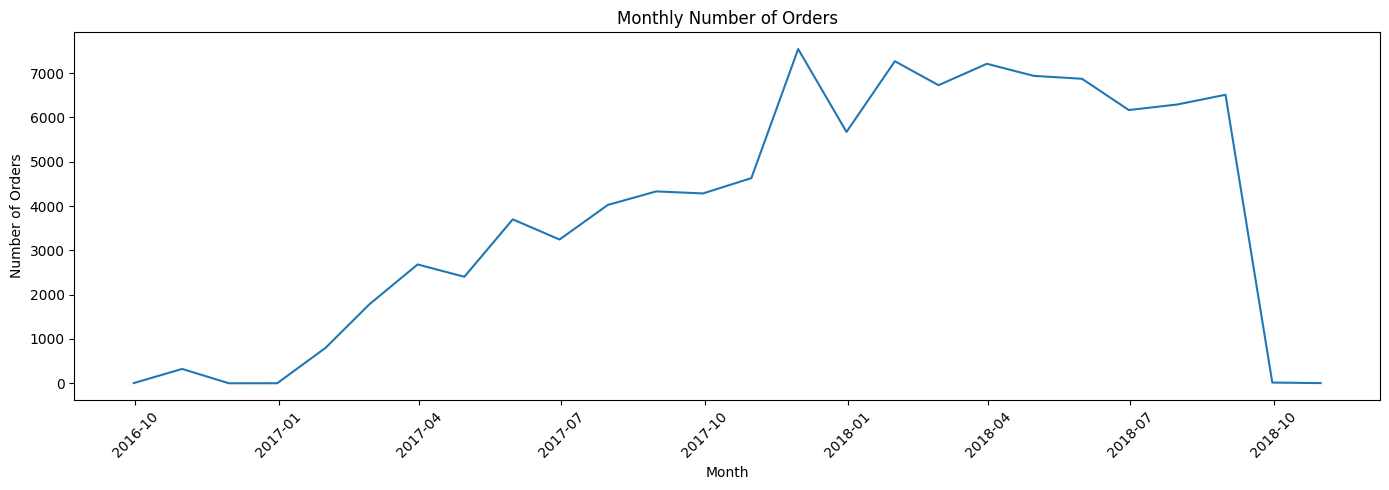

In [14]:
plt.figure(figsize=(14, 5))

plt.plot(monthly_orders.index, monthly_orders.values)

plt.title('Monthly Number of Orders')
plt.xlabel('Month')
plt.ylabel('Number of Orders')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [16]:
order_items['price'].describe()

count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

In [17]:
order_items['freight_value'].describe()

count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64

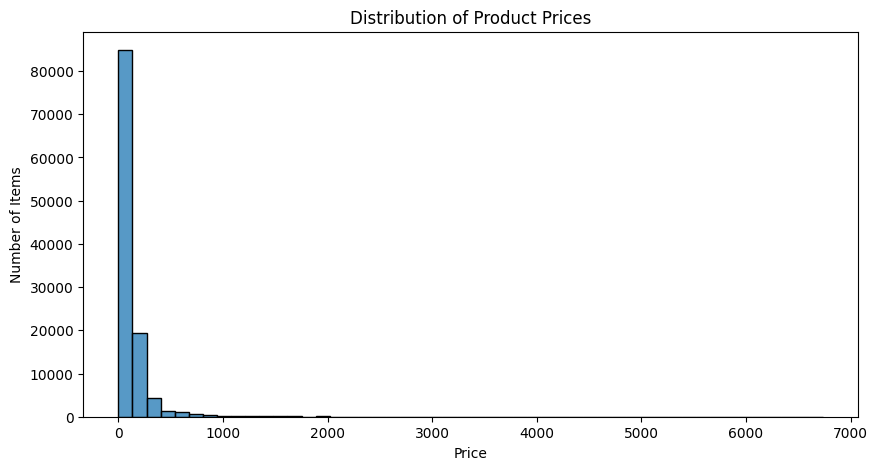

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(order_items['price'], bins=50)

plt.title('Distribution of Product Prices')
plt.xlabel('Price')
plt.ylabel('Number of Items')

plt.show()

In [19]:
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [20]:
orders['order_status'].value_counts(normalize=True) * 100

order_status
delivered      97.020344
shipped         1.113223
canceled        0.628513
unavailable     0.612423
invoiced        0.315765
processing      0.302692
created         0.005028
approved        0.002011
Name: proportion, dtype: float64

In [21]:
order_items['price'].describe()

count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

In [22]:
order_items['freight_value'].describe()

count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64

In [23]:
missing_orders = orders.isnull().sum().sort_values(ascending=False)
missing_orders[missing_orders>0]

order_delivered_customer_date    2965
order_delivered_carrier_date     1783
order_approved_at                 160
dtype: int64

In [24]:
missing_customers = customers.isnull().sum().sort_values(ascending=False)
missing_customers[missing_customers > 0]

Series([], dtype: int64)

In [25]:
missing_order_items = order_items.isnull().sum().sort_values(ascending=False)

missing_order_items[missing_order_items > 0]

Series([], dtype: int64)

In [26]:
missing_products = products.isnull().sum().sort_values(ascending=False)

missing_products[missing_products > 0]

product_category_name         610
product_description_lenght    610
product_name_lenght           610
product_photos_qty            610
product_weight_g                2
product_height_cm               2
product_length_cm               2
product_width_cm                2
dtype: int64

In [27]:
print("Customer duplicate rows:", customers.duplicated().sum())
print("Order duplicate rows:", orders.duplicated().sum())
print("Order item duplicate rows:", order_items.duplicated().sum())
print("Product duplicate rows:", products.duplicated().sum())
print("Payment duplicate rows:", payments.duplicated().sum())
print("Review duplicate rows:", reviews.duplicated().sum())

Customer duplicate rows: 0
Order duplicate rows: 0
Order item duplicate rows: 0
Product duplicate rows: 0
Payment duplicate rows: 0
Review duplicate rows: 0


In [28]:
print("Duplicate customer_id:",
      customers['customer_id'].duplicated().sum())

print("Duplicate order_id:",
      orders['order_id'].duplicated().sum())

print("Duplicate product_id:",
      products['product_id'].duplicated().sum())

Duplicate customer_id: 0
Duplicate order_id: 0
Duplicate product_id: 0


In [29]:
order_items['order_id'].duplicated().sum()

np.int64(13984)

In [30]:
orders_without_items = orders[
    ~orders['order_id'].isin(order_items['order_id'])
]

print("Orders without order items:", len(orders_without_items))

orders_without_items['order_status'].value_counts()

Orders without order items: 775


order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

In [31]:
Q1 = order_items['price'].quantile(0.25)
Q3 = order_items['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 39.9
Q3: 134.9
IQR: 95.0
Lower bound: -102.6
Upper bound: 277.4


In [32]:
price_outliers = order_items[
    (order_items['price'] < lower_bound) |
    (order_items['price'] > upper_bound)
]

print("Potential price outliers:", len(price_outliers))
print("Percentage:",
      len(price_outliers) / len(order_items) * 100)

Potential price outliers: 8427
Percentage: 7.480692410119841


In [33]:
price_outliers[
    ['order_id', 'product_id', 'price', 'freight_value']
].sort_values('price', ascending=False).head(10)

,order_id,product_id,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,489ae2aa008f021502940f251d4cce7f,6735.00,194.31
112233,fefacc66af859508bf1a7934eab1e97f,69c590f7ffc7bf8db97190b6cb6ed62e,6729.00,193.21
107841,f5136e38d1a14a4dbd87dff67da82701,1bdf5e6731585cf01aa8169c7028d6ad,6499.00,227.66
74336,a96610ab360d42a2e5335a3998b4718a,a6492cc69376c469ab6f61d8f44de961,4799.00,151.34
11249,199af31afc78c699f0dbf71fb178d4d4,c3ed642d592594bb648ff4a04cee2747,4690.00,74.34
62086,8dbc85d1447242f3b127dda390d56e19,259037a6a41845e455183f89c5035f18,4590.00,91.78
29193,426a9742b533fc6fed17d1fd6d143d7e,a1beef8f3992dbd4cd8726796aa69c53,4399.87,113.45
45843,68101694e5c5dc7330c91e1bbc36214f,6cdf8fc1d741c76586d8b6b15e9eef30,4099.99,75.27
78310,b239ca7cd485940b31882363b52e6674,dd113cb02b2af9c8e5787e8f1f0722f6,4059.00,104.51
59137,86c4eab1571921a6a6e248ed312f5a5a,6902c1962dd19d540807d0ab8fade5c6,3999.90,17.01


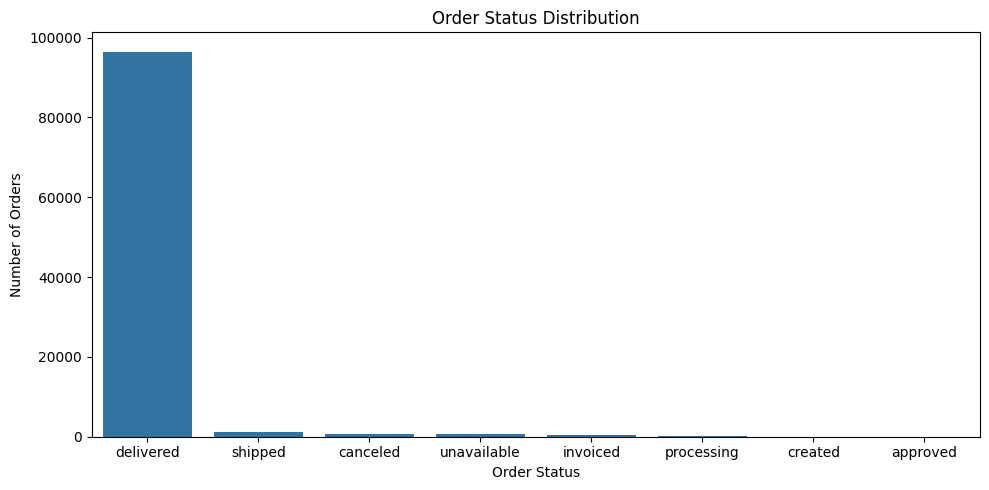

In [34]:
plt.figure(figsize=(10, 5))

status_counts = orders['order_status'].value_counts()

sns.barplot(
    x=status_counts.index,
    y=status_counts.values
)

plt.title('Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

In [35]:
#merging customers and orders 

customer_orders = customers.merge(
    orders,
    on='customer_id',
    how='inner'
)

print("Shape:", customer_orders.shape)
customer_orders.head()

Shape: (99441, 12)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,2018-03-28 16:04:25,2018-04-10
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,2018-08-09 20:55:48,2018-08-15


In [36]:
#adding order items

transaction_data = customer_orders.merge(
    order_items,
    on='order_id',
    how='inner'
)

print("Shape:", transaction_data.shape)
transaction_data.head()

Shape: (112650, 18)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05,1,a9516a079e37a9c9c36b9b78b10169e8,7c67e1448b00f6e969d365cea6b010ab,2017-05-22 15:22:12,124.99,21.88
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-01-18 20:58:32,289.00,46.48
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13,1,bd07b66896d6f1494f5b86251848ced7,7c67e1448b00f6e969d365cea6b010ab,2018-06-05 16:19:10,139.94,17.79
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,2018-03-28 16:04:25,2018-04-10,1,a5647c44af977b148e0a3a4751a09e2e,7c67e1448b00f6e969d365cea6b010ab,2018-03-27 16:31:16,149.94,23.36
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,2018-08-09 20:55:48,2018-08-15,1,9391a573abe00141c56e38d84d7d5b3b,4a3ca9315b744ce9f8e9374361493884,2018-07-31 10:10:09,230.00,22.25


In [37]:
#adding product info 

transaction_data = transaction_data.merge(
    products,
    on='product_id',
    how='left'
)

print("Shape:", transaction_data.shape)
transaction_data.head()

Shape: (112650, 26)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,...,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,...,124.99,21.88,moveis_escritorio,41.0,1141.0,1.0,8683.0,54.0,64.0,31.0
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,...,289.00,46.48,utilidades_domesticas,43.0,1002.0,3.0,10150.0,89.0,15.0,40.0
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,...,139.94,17.79,moveis_escritorio,55.0,955.0,1.0,8267.0,52.0,52.0,17.0
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,...,149.94,23.36,moveis_escritorio,48.0,1066.0,1.0,12160.0,56.0,51.0,28.0
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,...,230.00,22.25,casa_conforto,61.0,407.0,1.0,5200.0,45.0,15.0,35.0


In [38]:
print("Rows after merge:", len(transaction_data))
print("Unique orders:", transaction_data['order_id'].nunique())
print("Unique customers:", transaction_data['customer_unique_id'].nunique())
print("Unique products:", transaction_data['product_id'].nunique())

Rows after merge: 112650
Unique orders: 98666
Unique customers: 95420
Unique products: 32951


In [39]:
delivered_data = transaction_data[
    transaction_data['order_status'] == 'delivered'
].copy()

print("Delivered transaction rows:", len(delivered_data))
print("Unique delivered orders:", delivered_data['order_id'].nunique())
print("Unique customers:", delivered_data['customer_unique_id'].nunique())

Delivered transaction rows: 110197
Unique delivered orders: 96478
Unique customers: 93358


In [40]:
analysis_date = delivered_data['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

print("Analysis date:", analysis_date)

Analysis date: 2018-08-30 15:00:37


In [41]:
delivered_data['item_revenue'] = delivered_data['price']

In [42]:
rfm = delivered_data.groupby('customer_unique_id').agg(
    recency=('order_purchase_timestamp',
             lambda x: (analysis_date - x.max()).days),

    frequency=('order_id', 'nunique'),

    monetary=('item_revenue', 'sum')
).reset_index()

In [43]:
rfm.head()

,customer_unique_id,recency,frequency,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90
2,0000f46a3911fa3c0805444483337064,537,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00


In [44]:
rfm.shape

(93358, 4)

In [45]:
rfm[['recency', 'frequency', 'monetary']].isnull().sum()

recency      0
frequency    0
monetary     0
dtype: int64

In [46]:
rfm.sort_values('monetary', ascending=False).head(10)

,customer_unique_id,recency,frequency,monetary
3724,0a0a92112bd4c708ca5fde585afaa872,334,1,13440.0
79636,da122df9eeddfedc1dc1f5349a1a690c,515,2,7388.0
43168,763c8b1c9c68a0229c42c9fc6f662b93,46,1,7160.0
80463,dc4802a71eae9be1dd28f5d788ceb526,563,1,6735.0
25436,459bef486812aa25204be022145caa62,35,1,6729.0
93081,ff4159b92c40ebe40454e3e6a7c35ed6,462,1,6499.0
23411,4007669dec559734d6f53e029e360987,279,1,5934.6
87148,eebb5dda148d3893cdaf5b5ca3040ccb,498,1,4690.0
26640,48e1ac109decbb87765a3eade6854098,69,1,4590.0
59163,a229eba70ec1c2abef51f04987deb7a5,90,1,4400.0


In [47]:
rfm.sort_values('frequency', ascending=False).head(10)

,customer_unique_id,recency,frequency,monetary
51431,8d50f5eadf50201ccdcedfb9e2ac8455,9,15,714.63
22779,3e43e6105506432c953e165fb2acf44c,183,9,1000.85
36706,6469f99c1f9dfae7733b25662e7f1782,63,7,664.20
73921,ca77025e7201e3b30c44b472ff346268,90,7,806.61
10060,1b6c7548a2a1f9037c1fd3ddfed95f33,197,7,809.21
87885,f0e310a6839dce9de1638e0fe5ab282a,147,6,438.09
26257,47c1a3033b8b77b3ab6e109eb4d5fdf3,217,6,836.60
6964,12f5d6e1cbf93dafd9dcc19095df0b3d,601,6,58.40
36500,63cfc61cee11cbe306bff5857d00bfe4,93,6,579.81
80538,dc813062e0fc23409cd255f7f53c7074,7,6,687.76


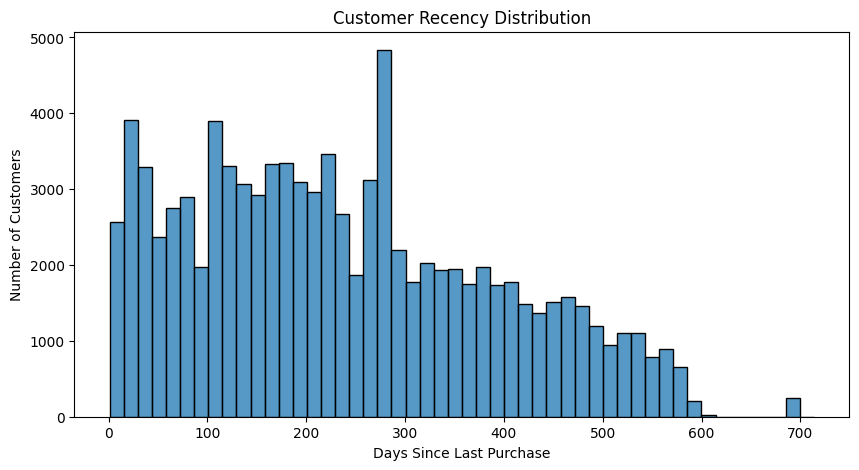

In [48]:
plt.figure(figsize=(10, 5))

sns.histplot(rfm['recency'], bins=50)

plt.title('Customer Recency Distribution')
plt.xlabel('Days Since Last Purchase')
plt.ylabel('Number of Customers')

plt.show()

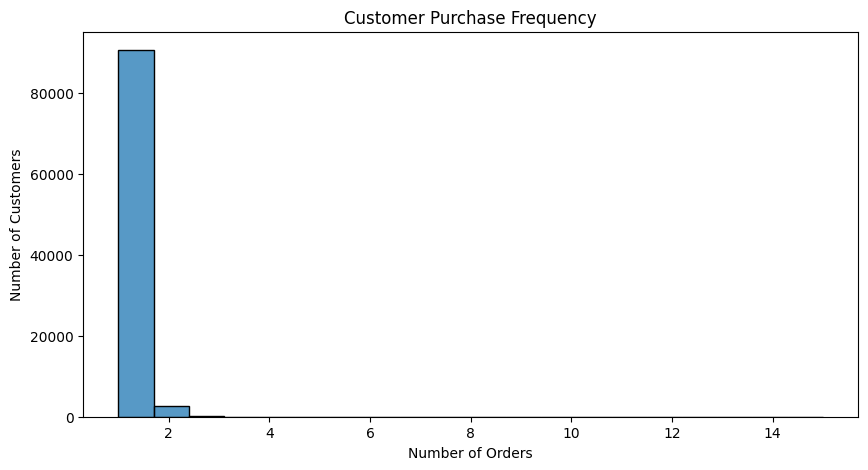

In [49]:
plt.figure(figsize=(10, 5))

sns.histplot(rfm['frequency'], bins=20)

plt.title('Customer Purchase Frequency')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers')

plt.show()

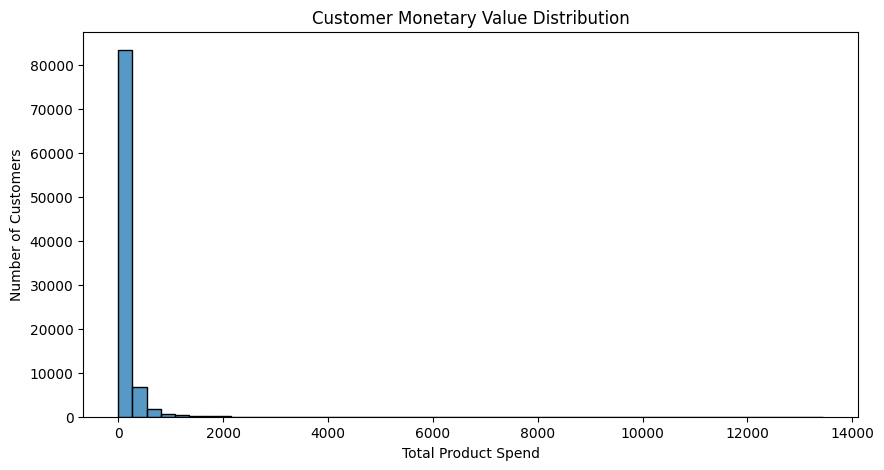

In [50]:
plt.figure(figsize=(10, 5))

sns.histplot(rfm['monetary'], bins=50)

plt.title('Customer Monetary Value Distribution')
plt.xlabel('Total Product Spend')
plt.ylabel('Number of Customers')

plt.show()

In [51]:
avg_order_value = (
    delivered_data.groupby('customer_unique_id')['item_revenue']
    .sum()
    /
    delivered_data.groupby('customer_unique_id')['order_id']
    .nunique()
)

In [52]:
rfm['avg_order_value'] = rfm['customer_unique_id'].map(avg_order_value)

In [53]:
rfm.head()

,customer_unique_id,recency,frequency,monetary,avg_order_value
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,18.90
2,0000f46a3911fa3c0805444483337064,537,1,69.00,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,25.99
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,180.00


In [54]:
rfm.shape


(93358, 5)

In [55]:
rfm.describe()


,recency,frequency,monetary,avg_order_value
count,93358.000000,93358.000000,93358.000000,93358.000000
mean,237.941773,1.033420,141.621480,137.508262
std,152.591453,0.209097,215.694014,209.860279
min,1.000000,1.000000,0.850000,0.850000
25%,114.000000,1.000000,47.650000,46.000000
50%,219.000000,1.000000,89.730000,86.990000
75%,346.000000,1.000000,154.737500,149.900000
max,714.000000,15.000000,13440.000000,13440.000000


In [56]:
rfm[['recency', 'frequency', 'monetary', 'avg_order_value']].skew()

recency             0.447434
frequency          11.095156
monetary            9.746869
avg_order_value     9.931195
dtype: float64

In [57]:
rfm_model = rfm.copy()

rfm_model['recency_log'] = np.log1p(rfm_model['recency'])
rfm_model['frequency_log'] = np.log1p(rfm_model['frequency'])
rfm_model['monetary_log'] = np.log1p(rfm_model['monetary'])
rfm_model['avg_order_value_log'] = np.log1p(
    rfm_model['avg_order_value']
)

In [58]:
rfm_model[
    ['recency_log',
     'frequency_log',
     'monetary_log',
     'avg_order_value_log']
].skew()

recency_log           -1.224108
frequency_log          6.522068
monetary_log           0.279788
avg_order_value_log    0.291204
dtype: float64

In [59]:
    rfm[['recency', 'frequency', 'monetary', 'avg_order_value']].corr()

,recency,frequency,monetary,avg_order_value
recency,1.000000,-0.022238,-0.000331,0.002947
frequency,-0.022238,1.000000,0.105775,-0.010991
monetary,-0.000331,0.105775,1.000000,0.985148
avg_order_value,0.002947,-0.010991,0.985148,1.000000


In [60]:
#Create the modeling matrix

features = [
    'recency_log',
    'frequency_log',
    'monetary_log'
]

X = rfm_model[features].copy()

X.head()

,recency_log,frequency_log,monetary_log
0,4.727388,0.693147,4.874434
1,4.753590,0.693147,2.990720
2,6.287859,0.693147,4.248495
3,5.774552,0.693147,3.295466
4,5.666427,0.693147,5.198497


In [61]:
X.describe()

,recency_log,frequency_log,monetary_log
count,93358.000000,93358.000000,93358.000000
mean,5.166297,0.706198,4.485786
std,0.933064,0.076683,0.923466
min,0.693147,0.693147,0.615186
25%,4.744932,0.693147,3.884652
50%,5.393628,0.693147,4.507888
75%,5.849325,0.693147,5.048172
max,6.572283,2.772589,9.506065


In [62]:
#standardizing

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

X_scaled.head()

,recency_log,frequency_log,monetary_log
0,-0.470398,-0.17019,0.420860
1,-0.442315,-0.17019,-1.618982
2,1.202027,-0.17019,-0.256958
3,0.651893,-0.17019,-1.288977
4,0.536011,-0.17019,0.771782


In [63]:
rfm[['recency', 'frequency', 'monetary', 'avg_order_value']].corr()


,recency,frequency,monetary,avg_order_value
recency,1.000000,-0.022238,-0.000331,0.002947
frequency,-0.022238,1.000000,0.105775,-0.010991
monetary,-0.000331,0.105775,1.000000,0.985148
avg_order_value,0.002947,-0.010991,0.985148,1.000000


In [64]:
X_scaled.describe()

,recency_log,frequency_log,monetary_log
count,9.335800e+04,9.335800e+04,9.335800e+04
mean,-1.697698e-15,8.084347e-16,5.094387e-16
std,1.000005e+00,1.000005e+00,1.000005e+00
min,-4.794069e+00,-1.701897e-01,-4.191407e+00
25%,-4.515947e-01,-1.701897e-01,-6.509581e-01
50%,2.436404e-01,-1.701897e-01,2.393372e-02
75%,7.320309e-01,-1.701897e-01,6.089979e-01
max,1.506856e+00,2.694733e+01,5.436374e+00


# Elbow method


In [65]:
inertia = []

k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

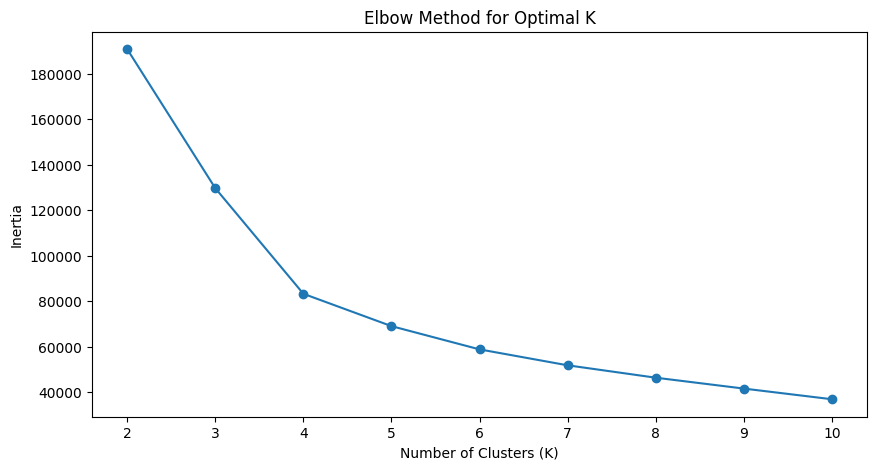

In [66]:
plt.figure(figsize=(10, 5))

plt.plot(k_range, inertia, marker='o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')

plt.xticks(list(k_range))
plt.show()

# slihoutescore

In [67]:
from sklearn.utils import resample

# Use a representative sample for silhouette calculation
sample_size = 10000

X_sample = X_scaled.sample(
    n=sample_size,
    random_state=42
)

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels_sample = kmeans.fit_predict(X_sample)
    
    score = silhouette_score(
        X_sample,
        labels_sample
    )
    
    silhouette_scores.append(score)
    
    print(f"K={k}: Silhouette Score={score:.4f}")

K=2: Silhouette Score=0.7121
K=3: Silhouette Score=0.4137
K=4: Silhouette Score=0.3915
K=5: Silhouette Score=0.3496
K=6: Silhouette Score=0.3492
K=7: Silhouette Score=0.3498
K=8: Silhouette Score=0.3440
K=9: Silhouette Score=0.3455
K=10: Silhouette Score=0.3459


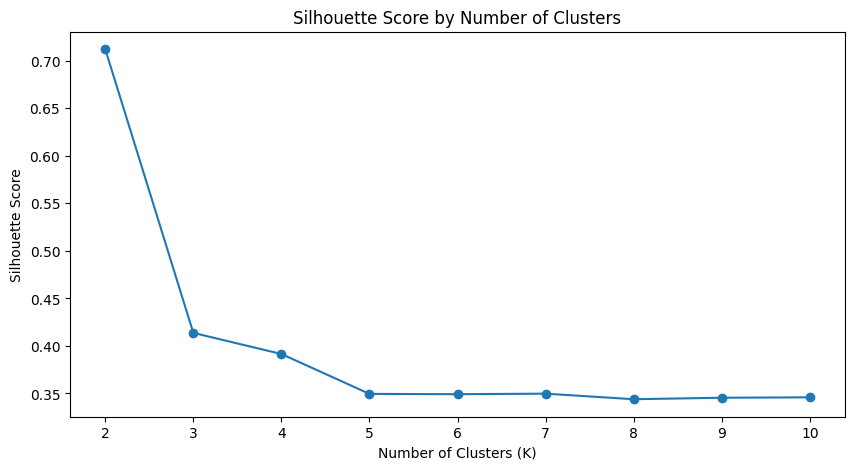

In [68]:
plt.figure(figsize=(10, 5))

plt.plot(
    k_range,
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Score by Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')

plt.xticks(list(k_range))
plt.show()

In [69]:
for k, inertia_value, silhouette in zip(
    k_range,
    inertia,
    silhouette_scores
):
    print(
        f"K={k}: "
        f"Inertia={inertia_value:.2f}, "
        f"Silhouette={silhouette:.4f}"
    )

K=2: Inertia=190706.20, Silhouette=0.7121
K=3: Inertia=129655.64, Silhouette=0.4137
K=4: Inertia=83293.57, Silhouette=0.3915
K=5: Inertia=69095.07, Silhouette=0.3496
K=6: Inertia=58882.79, Silhouette=0.3492
K=7: Inertia=51892.24, Silhouette=0.3498
K=8: Inertia=46453.60, Silhouette=0.3440
K=9: Inertia=41672.78, Silhouette=0.3455
K=10: Inertia=36992.84, Silhouette=0.3459


In [70]:
final_k = 4

kmeans_final = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

rfm_model['cluster'] = kmeans_final.fit_predict(X_scaled)

print("K-Means model trained successfully!")

K-Means model trained successfully!


In [71]:
cluster_counts = rfm_model['cluster'].value_counts().sort_index()

print(cluster_counts)

cluster
0    37747
1    36704
2     2801
3    16106
Name: count, dtype: int64


In [72]:
cluster_percentages = (
    rfm_model['cluster']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(cluster_percentages.round(2))

cluster
0    40.43
1    39.32
2     3.00
3    17.25
Name: proportion, dtype: float64


In [73]:
#createing segment profile
segment_profile = (
    rfm_model
    .groupby('cluster')
    .agg(
        customers=('customer_unique_id', 'count'),
        avg_recency=('recency', 'mean'),
        avg_frequency=('frequency', 'mean'),
        avg_monetary=('monetary', 'mean'),
        avg_order_value=('avg_order_value', 'mean')
    )
    .round(2)
)

segment_profile

,customers,avg_recency,avg_frequency,avg_monetary,avg_order_value
cluster,,,,,
0,37747,278.01,1.00,237.20,237.20
1,36704,284.11,1.00,45.13,45.13
2,2801,220.29,2.11,260.05,122.96
3,16106,41.89,1.00,116.90,116.90


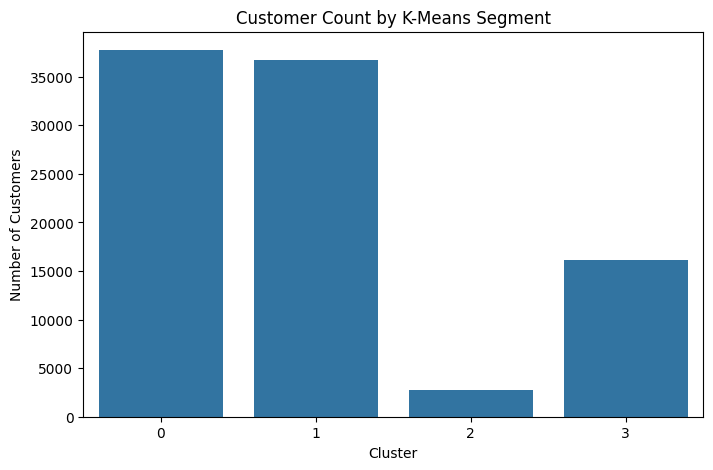

In [74]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title('Customer Count by K-Means Segment')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')

plt.show()

In [75]:
#PCA

pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:",
      pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.38252364 0.33322392]
Total explained variance: 0.715747561223389


In [76]:
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

pca_df['cluster'] = rfm_model['cluster'].values

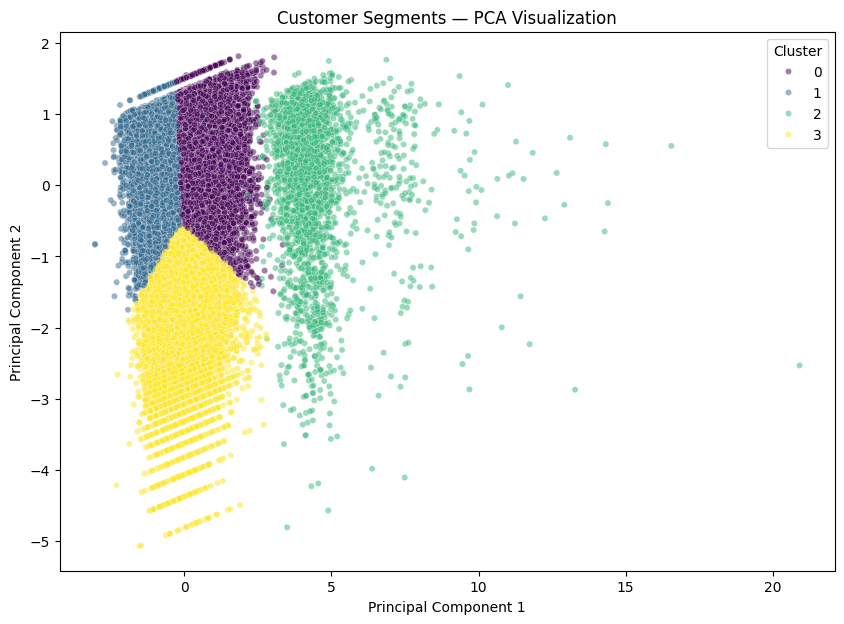

In [77]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette='viridis',
    alpha=0.5,
    s=20
)

plt.title('Customer Segments — PCA Visualization')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.legend(title='Cluster')
plt.show()

In [78]:
#segments

segment_names = {
    0: 'High-Value Inactive',
    1: 'Low-Value Inactive',
    2: 'Repeat High-Value',
    3: 'Recent Customers'
}

rfm_model['segment'] = rfm_model['cluster'].map(segment_names)

rfm_model[['cluster', 'segment']].drop_duplicates().sort_values('cluster')

,cluster,segment
0,0,High-Value Inactive
1,1,Low-Value Inactive
104,2,Repeat High-Value
19,3,Recent Customers


In [79]:
final_segment_profile = (
    rfm_model
    .groupby(['cluster', 'segment'])
    .agg(
        customers=('customer_unique_id', 'count'),
        avg_recency=('recency', 'mean'),
        avg_frequency=('frequency', 'mean'),
        avg_monetary=('monetary', 'mean'),
        avg_order_value=('avg_order_value', 'mean')
    )
    .round(2)
)

final_segment_profile

,,customers,avg_recency,avg_frequency,avg_monetary,avg_order_value
cluster,segment,,,,,
0,High-Value Inactive,37747,278.01,1.00,237.20,237.20
1,Low-Value Inactive,36704,284.11,1.00,45.13,45.13
2,Repeat High-Value,2801,220.29,2.11,260.05,122.96
3,Recent Customers,16106,41.89,1.00,116.90,116.90


## DBSCAN

In [80]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=10,
    n_jobs=-1
)

dbscan_labels = dbscan.fit_predict(X_scaled)

print("DBSCAN completed.")

DBSCAN completed.


In [81]:
dbscan_counts = pd.Series(dbscan_labels).value_counts().sort_index()

print(dbscan_counts)

-1      107
 0    90539
 1     2557
 2      143
 3       12
Name: count, dtype: int64


In [82]:
noise_count = (dbscan_labels == -1).sum()

print("Noise points:", noise_count)
print("Noise percentage:",
      round(noise_count / len(dbscan_labels) * 100, 2), "%")

Noise points: 107
Noise percentage: 0.11 %


In [83]:
# Create a sample from the DBSCAN results
dbscan_eval = pd.DataFrame({
    'cluster': dbscan_labels
}, index=X_scaled.index)

dbscan_eval = dbscan_eval[dbscan_eval['cluster'] != -1]

sample_n = min(10000, len(dbscan_eval))

dbscan_sample = dbscan_eval.sample(
    n=sample_n,
    random_state=42
)

X_dbscan_sample = X_scaled.loc[dbscan_sample.index]
labels_dbscan_sample = dbscan_sample['cluster'].values

if len(np.unique(labels_dbscan_sample)) > 1:
    dbscan_silhouette = silhouette_score(
        X_dbscan_sample,
        labels_dbscan_sample
    )
    print("DBSCAN Silhouette Score:", round(dbscan_silhouette, 4))
else:
    print("Silhouette score cannot be calculated because only one cluster is present.")

DBSCAN Silhouette Score: 0.6906


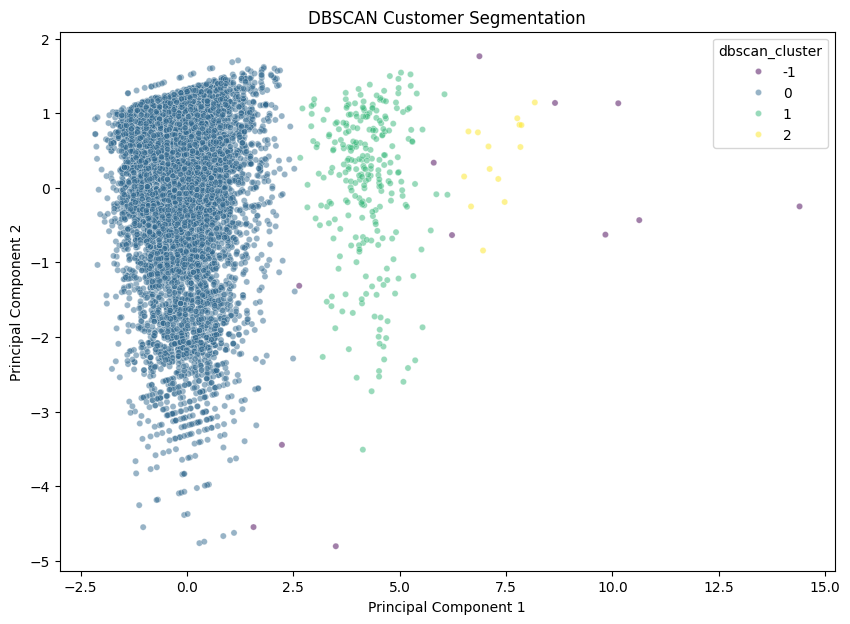

In [84]:
dbscan_pca = pca_df.copy()

dbscan_pca['dbscan_cluster'] = dbscan_labels

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=dbscan_pca.sample(10000, random_state=42),
    x='PC1',
    y='PC2',
    hue='dbscan_cluster',
    palette='viridis',
    alpha=0.5,
    s=20
)

plt.title('DBSCAN Customer Segmentation')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.show()

# hierarchical sample

In [85]:
hier_sample_size = 10000

hier_indices = X_scaled.sample(
    n=hier_sample_size,
    random_state=42
).index

X_hier = X_scaled.loc[hier_indices]

print("Hierarchical clustering sample:", X_hier.shape)

Hierarchical clustering sample: (10000, 3)


# Agglomerative Clustering

In [86]:
hierarchical = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

hier_labels = hierarchical.fit_predict(X_hier)

print("Hierarchical clustering completed.")
print(pd.Series(hier_labels).value_counts().sort_index())

Hierarchical clustering completed.
0    3247
1    2027
2    4433
3     293
Name: count, dtype: int64


In [87]:
hier_silhouette = silhouette_score(
    X_hier,
    hier_labels
)

print(
    "Hierarchical Silhouette Score:",
    round(hier_silhouette, 4)
)

Hierarchical Silhouette Score: 0.3207


In [88]:
hier_counts = pd.Series(
    hier_labels
).value_counts().sort_index()

print(hier_counts)

0    3247
1    2027
2    4433
3     293
Name: count, dtype: int64


In [89]:
clustering_comparison = pd.DataFrame({
    'Algorithm': [
        'K-Means',
        'DBSCAN',
        'Hierarchical'
    ],
    'Silhouette_Score': [
        silhouette_scores[2],  # K=4
        dbscan_silhouette,
        hier_silhouette
    ]
})

clustering_comparison

,Algorithm,Silhouette_Score
0,K-Means,0.391516
1,DBSCAN,0.690632
2,Hierarchical,0.320740


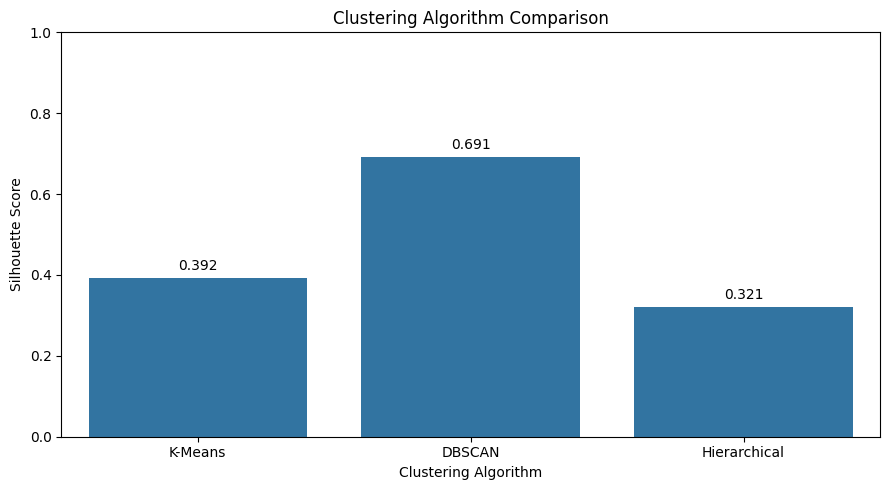

In [90]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=clustering_comparison,
    x='Algorithm',
    y='Silhouette_Score'
)

plt.title('Clustering Algorithm Comparison')
plt.xlabel('Clustering Algorithm')
plt.ylabel('Silhouette Score')

plt.ylim(0, 1)

for i, score in enumerate(clustering_comparison['Silhouette_Score']):
    plt.text(
        i,
        score + 0.02,
        f'{score:.3f}',
        ha='center'
    )

plt.tight_layout()
plt.show()

In [91]:
#saving customer segment dataset

customer_segments = rfm_model[
    [
        'customer_unique_id',
        'recency',
        'frequency',
        'monetary',
        'avg_order_value',
        'cluster',
        'segment'
    ]
].copy()

customer_segments.head()

,customer_unique_id,recency,frequency,monetary,avg_order_value,cluster,segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,129.90,0,High-Value Inactive
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,18.90,1,Low-Value Inactive
2,0000f46a3911fa3c0805444483337064,537,1,69.00,69.00,1,Low-Value Inactive
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,25.99,1,Low-Value Inactive
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,180.00,0,High-Value Inactive


In [92]:
print("Customers:", len(customer_segments))
print("Columns:", customer_segments.columns.tolist())

Customers: 93358
Columns: ['customer_unique_id', 'recency', 'frequency', 'monetary', 'avg_order_value', 'cluster', 'segment']


In [93]:
#########demographics

In [94]:
customer_demo = (
    customer_orders[
        [
            'customer_unique_id',
            'customer_city',
            'customer_state'
        ]
    ]
    .drop_duplicates('customer_unique_id')
)

In [95]:
customer_segments = customer_segments.merge(
    customer_demo,
    on='customer_unique_id',
    how='left'
)

customer_segments.head()

,customer_unique_id,recency,frequency,monetary,avg_order_value,cluster,segment,customer_city,customer_state
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,129.90,0,High-Value Inactive,cajamar,SP
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,18.90,1,Low-Value Inactive,osasco,SP
2,0000f46a3911fa3c0805444483337064,537,1,69.00,69.00,1,Low-Value Inactive,sao jose,SC
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,25.99,1,Low-Value Inactive,belem,PA
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,180.00,0,High-Value Inactive,sorocaba,SP


In [96]:
customer_segments[['customer_unique_id',
                   'segment',
                   'customer_city',
                   'customer_state']].head()

,customer_unique_id,segment,customer_city,customer_state
0,0000366f3b9a7992bf8c76cfdf3221e2,High-Value Inactive,cajamar,SP
1,0000b849f77a49e4a4ce2b2a4ca5be3f,Low-Value Inactive,osasco,SP
2,0000f46a3911fa3c0805444483337064,Low-Value Inactive,sao jose,SC
3,0000f6ccb0745a6a4b88665a16c9f078,Low-Value Inactive,belem,PA
4,0004aac84e0df4da2b147fca70cf8255,High-Value Inactive,sorocaba,SP


In [97]:
state_profile = pd.crosstab(
    customer_segments['segment'],
    customer_segments['customer_state'],
    normalize='index'
) * 100

state_profile.round(2)

customer_state,AC,AL,AM,AP,BA,CE,DF,ES,GO,MA,...,PR,RJ,RN,RO,RR,RS,SC,SE,SP,TO
segment,,,,,,,,,,,,,,,,,,,,,
High-Value Inactive,0.09,0.52,0.15,0.10,3.64,1.57,2.15,2.12,2.21,0.86,...,5.01,13.86,0.59,0.32,0.05,5.71,3.87,0.39,38.01,0.35
Low-Value Inactive,0.08,0.34,0.14,0.05,3.23,1.27,2.04,2.11,1.96,0.73,...,5.23,12.14,0.44,0.20,0.05,5.64,3.77,0.32,43.71,0.23
Recent Customers,0.06,0.35,0.17,0.06,3.16,1.10,2.48,1.84,1.75,0.57,...,5.07,11.39,0.43,0.16,0.02,4.86,3.17,0.36,46.78,0.27
Repeat High-Value,0.14,0.36,0.11,0.04,3.18,0.71,2.11,2.00,2.11,0.50,...,5.07,13.85,0.36,0.32,0.04,5.68,3.28,0.29,43.66,0.25


In [98]:
top_states_by_segment = (
    customer_segments
    .groupby(['segment', 'customer_state'])
    .size()
    .reset_index(name='customers')
)

top_states_by_segment = (
    top_states_by_segment
    .sort_values(
        ['segment', 'customers'],
        ascending=[True, False]
    )
    .groupby('segment')
    .head(5)
)

top_states_by_segment

,segment,customer_state,customers
25,High-Value Inactive,SP,14348
18,High-Value Inactive,RJ,5233
10,High-Value Inactive,MG,4611
22,High-Value Inactive,RS,2156
17,High-Value Inactive,PR,1892
52,Low-Value Inactive,SP,16044
45,Low-Value Inactive,RJ,4455
37,Low-Value Inactive,MG,4283
49,Low-Value Inactive,RS,2070
44,Low-Value Inactive,PR,1919


# Prepare the basket data

In [99]:
delivered_data['product_category_name'].isnull().sum()

np.int64(1537)

In [100]:
print(
    "Unique product categories:",
    delivered_data['product_category_name'].nunique()
)

Unique product categories: 73


In [101]:
delivered_data['product_category_name'].value_counts().head(20)

product_category_name
cama_mesa_banho                10953
beleza_saude                    9465
esporte_lazer                   8431
moveis_decoracao                8160
informatica_acessorios          7644
utilidades_domesticas           6795
relogios_presentes              5859
telefonia                       4430
ferramentas_jardim              4268
automotivo                      4140
brinquedos                      4030
cool_stuff                      3718
perfumaria                      3340
bebes                           2982
eletronicos                     2729
papelaria                       2466
fashion_bolsas_e_acessorios     1985
pet_shop                        1924
moveis_escritorio               1668
consoles_games                  1089
Name: count, dtype: int64

In [102]:
basket_data = delivered_data.copy()

basket_data['product_category_name'] = (
    basket_data['product_category_name']
    .fillna('unknown')
)

In [103]:
basket = (
    basket_data
    .groupby(['order_id', 'product_category_name'])
    .size()
    .unstack(fill_value=0)
)

In [104]:
basket = basket.applymap(
    lambda x: 1 if x > 0 else 0
)

In [105]:
basket.head()

product_category_name,agro_industria_e_comercio,alimentos,alimentos_bebidas,artes,artes_e_artesanato,artigos_de_festas,artigos_de_natal,audio,automotivo,bebes,...,portateis_casa_forno_e_cafe,portateis_cozinha_e_preparadores_de_alimentos,relogios_presentes,seguros_e_servicos,sinalizacao_e_seguranca,tablets_impressao_imagem,telefonia,telefonia_fixa,unknown,utilidades_domesticas
order_id,,,,,,,,,,,,,,,,,,,,,
00010242fe8c5a6d1ba2dd792cb16214,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
00018f77f2f0320c557190d7a144bdd3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
000229ec398224ef6ca0657da4fc703e,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
00024acbcdf0a6daa1e931b038114c75,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
00042b26cf59d7ce69dfabb4e55b4fd9,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [106]:
print("Basket shape:", basket.shape)

Basket shape: (96478, 74)


# Apriori

In [107]:
product_frequency = (
    delivered_data['product_id']
    .value_counts()
)

print("Total unique products:", product_frequency.size)

top_products = product_frequency.head(100)

print("\nTop 20 most frequently purchased products:")
display(top_products.head(20))

Total unique products: 32216

Top 20 most frequently purchased products:


product_id
aca2eb7d00ea1a7b8ebd4e68314663af    520
422879e10f46682990de24d770e7f83d    484
99a4788cb24856965c36a24e339b6058    477
389d119b48cf3043d311335e499d9c6b    390
368c6c730842d78016ad823897a372db    388
53759a2ecddad2bb87a079a1f1519f73    373
d1c427060a0f73f6b889a5c7c61f2ac4    332
53b36df67ebb7c41585e8d54d6772e08    321
154e7e31ebfa092203795c972e5804a6    274
3dd2a17168ec895c781a9191c1e95ad7    272
2b4609f8948be18874494203496bc318    255
a62e25e09e05e6faf31d90c6ec1aa3d1    224
7c1bd920dbdf22470b68bde975dd3ccf    220
bb50f2e236e5eea0100680137654686c    194
e0d64dcfaa3b6db5c54ca298ae101d05    193
5a848e4ab52fd5445cdc07aab1c40e48    190
e53e557d5a159f5aa2c5e995dfdf244b    181
42a2c92a0979a949ca4ea89ec5c7b934    177
b532349fe46b38fbc7bb3914c1bdae07    166
35afc973633aaeb6b877ff57b2793310    162
Name: count, dtype: int64

In [108]:
top_100_share = (
    top_products.sum() /
    product_frequency.sum()
) * 100

print(
    f"Top 100 products account for "
    f"{top_100_share:.2f}% of all product-item purchases."
)

Top 100 products account for 12.78% of all product-item purchases.


In [109]:
# ============================================
# MARKET BASKET ANALYSIS
# STEP 2: CREATE PRODUCT BASKET
# ============================================

top_product_ids = set(top_products.index)

product_basket_data = delivered_data[
    delivered_data['product_id'].isin(top_product_ids)
].copy()

print("Rows after keeping top 100 products:",
      len(product_basket_data))

print("Orders represented:",
      product_basket_data['order_id'].nunique())

print("Products represented:",
      product_basket_data['product_id'].nunique())

Rows after keeping top 100 products: 14079
Orders represented: 12440
Products represented: 100


In [110]:
product_basket = (
    product_basket_data
    .groupby(['order_id', 'product_id'])
    .size()
    .unstack(fill_value=0)
)

# Convert quantity/count to 1/0
product_basket = product_basket.applymap(
    lambda x: 1 if x > 0 else 0
)

print("Product basket shape:", product_basket.shape)

Product basket shape: (12440, 100)


In [111]:
product_basket_size = product_basket.sum(axis=1)

print("Orders with at least 1 top product:",
      len(product_basket_size))

print("Orders with 2+ top products:",
      (product_basket_size >= 2).sum())

print("Orders with 3+ top products:",
      (product_basket_size >= 3).sum())

print("Maximum top products in one order:",
      product_basket_size.max())

Orders with at least 1 top product: 12440
Orders with 2+ top products: 160
Orders with 3+ top products: 8
Maximum top products in one order: 4


In [112]:
frequent_itemsets = apriori(
    product_basket,
    min_support=0.001,
    use_colnames=True
)

print("Total frequent itemsets:", len(frequent_itemsets))

pair_itemsets = frequent_itemsets[
    frequent_itemsets['itemsets'].apply(len) >= 2
].sort_values(
    'support',
    ascending=False
)

print("Multi-product itemsets:", len(pair_itemsets))

display(pair_itemsets.head(30))

Total frequent itemsets: 102
Multi-product itemsets: 2


,support,itemsets
101,0.002733,"(e53e557d5a159f5aa2c5e995dfdf244b, 36f60d45225..."
100,0.002331,"(35afc973633aaeb6b877ff57b2793310, 99a4788cb24..."


In [113]:
if len(pair_itemsets) > 0:

    rules = association_rules(
        frequent_itemsets,
        metric='confidence',
        min_threshold=0.05
    )

    rules = rules.sort_values(
        'lift',
        ascending=False
    )

    print("Total association rules:", len(rules))

    display(
        rules[
            [
                'antecedents',
                'consequents',
                'support',
                'confidence',
                'lift'
            ]
        ].head(30)
    )

else:
    print("No multi-product itemsets found.")

Total association rules: 4


,antecedents,consequents,support,confidence,lift
3,(36f60d45225e60c7da4558b070ce4b60),(e53e557d5a159f5aa2c5e995dfdf244b),0.002733,0.309091,24.968123
2,(e53e557d5a159f5aa2c5e995dfdf244b),(36f60d45225e60c7da4558b070ce4b60),0.002733,0.220779,24.968123
1,(99a4788cb24856965c36a24e339b6058),(35afc973633aaeb6b877ff57b2793310),0.002331,0.063596,5.170852
0,(35afc973633aaeb6b877ff57b2793310),(99a4788cb24856965c36a24e339b6058),0.002331,0.189542,5.170852


In [114]:
product_category_map = (
    products[
        ['product_id', 'product_category_name']
    ]
    .drop_duplicates('product_id')
    .set_index('product_id')['product_category_name']
    .to_dict()
)

In [115]:
rules_readable = rules[
    [
        'antecedents',
        'consequents',
        'support',
        'confidence',
        'lift'
    ]
].copy()

rules_readable['antecedents'] = rules_readable[
    'antecedents'
].apply(
    lambda x: [
        product_category_map.get(product, product)
        for product in x
    ]
)

rules_readable['consequents'] = rules_readable[
    'consequents'
].apply(
    lambda x: [
        product_category_map.get(product, product)
        for product in x
    ]
)

rules_readable['antecedents'] = rules_readable[
    'antecedents'
].apply(lambda x: ', '.join(x))

rules_readable['consequents'] = rules_readable[
    'consequents'
].apply(lambda x: ', '.join(x))

display(
    rules_readable.sort_values(
        'lift',
        ascending=False
    )
)

,antecedents,consequents,support,confidence,lift
3,informatica_acessorios,informatica_acessorios,0.002733,0.309091,24.968123
2,informatica_acessorios,informatica_acessorios,0.002733,0.220779,24.968123
1,cama_mesa_banho,casa_conforto,0.002331,0.063596,5.170852
0,casa_conforto,cama_mesa_banho,0.002331,0.189542,5.170852


In [116]:
association_rules_final = rules_readable.copy()

association_rules_final['support'] = (
    association_rules_final['support'] * 100
).round(3)

association_rules_final['confidence'] = (
    association_rules_final['confidence'] * 100
).round(2)

association_rules_final['lift'] = (
    association_rules_final['lift']
).round(2)

association_rules_final = association_rules_final.rename(
    columns={
        'support': 'Support (%)',
        'confidence': 'Confidence (%)',
        'lift': 'Lift'
    }
)

association_rules_final

,antecedents,consequents,Support (%),Confidence (%),Lift
3,informatica_acessorios,informatica_acessorios,0.273,30.91,24.97
2,informatica_acessorios,informatica_acessorios,0.273,22.08,24.97
1,cama_mesa_banho,casa_conforto,0.233,6.36,5.17
0,casa_conforto,cama_mesa_banho,0.233,18.95,5.17


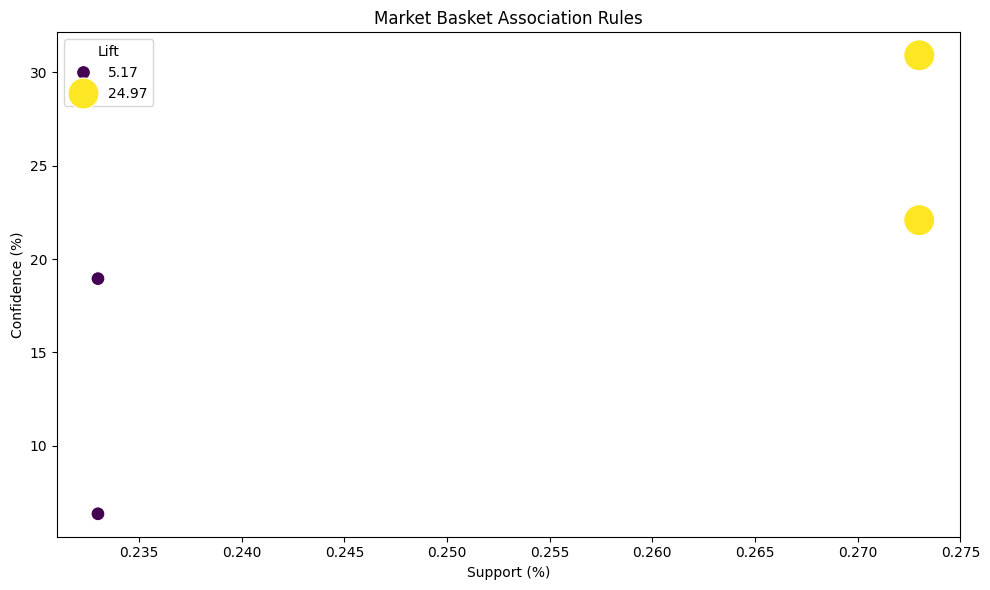

In [117]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=association_rules_final,
    x='Support (%)',
    y='Confidence (%)',
    size='Lift',
    hue='Lift',
    sizes=(100, 500),
    palette='viridis'
)

plt.title('Market Basket Association Rules')
plt.xlabel('Support (%)')
plt.ylabel('Confidence (%)')

plt.tight_layout()
plt.show()

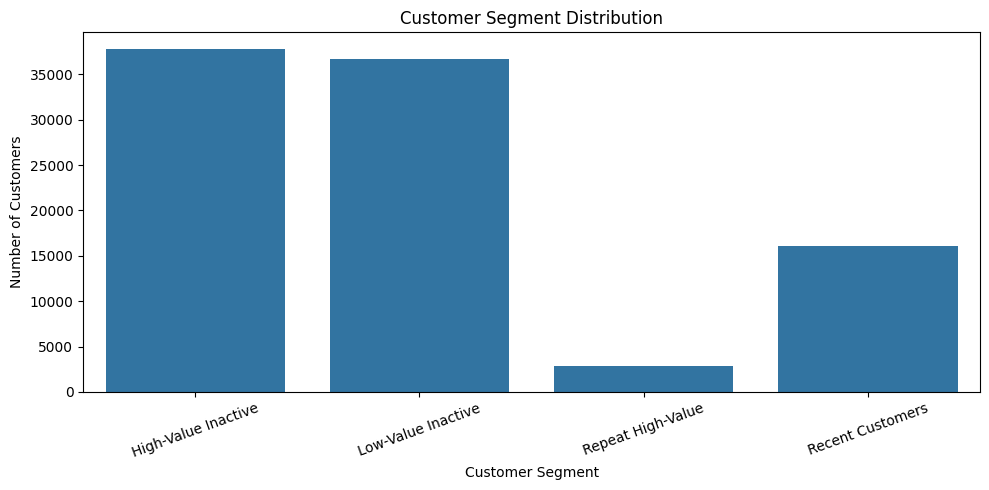

In [118]:
plt.figure(figsize=(10, 5))

segment_counts = (
    customer_segments['segment']
    .value_counts()
    .reindex([
        'High-Value Inactive',
        'Low-Value Inactive',
        'Repeat High-Value',
        'Recent Customers'
    ])
)

sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values
)

plt.title('Customer Segment Distribution')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [119]:
segment_metrics = (
    customer_segments
    .groupby('segment')
    [['recency', 'frequency', 'monetary']]
    .mean()
    .reindex([
        'High-Value Inactive',
        'Low-Value Inactive',
        'Repeat High-Value',
        'Recent Customers'
    ])
)

segment_metrics

,recency,frequency,monetary
segment,,,
High-Value Inactive,278.013749,1.000000,237.204159
Low-Value Inactive,284.108762,1.000000,45.133364
Repeat High-Value,220.294538,2.113888,260.053106
Recent Customers,41.885633,1.000000,116.898606


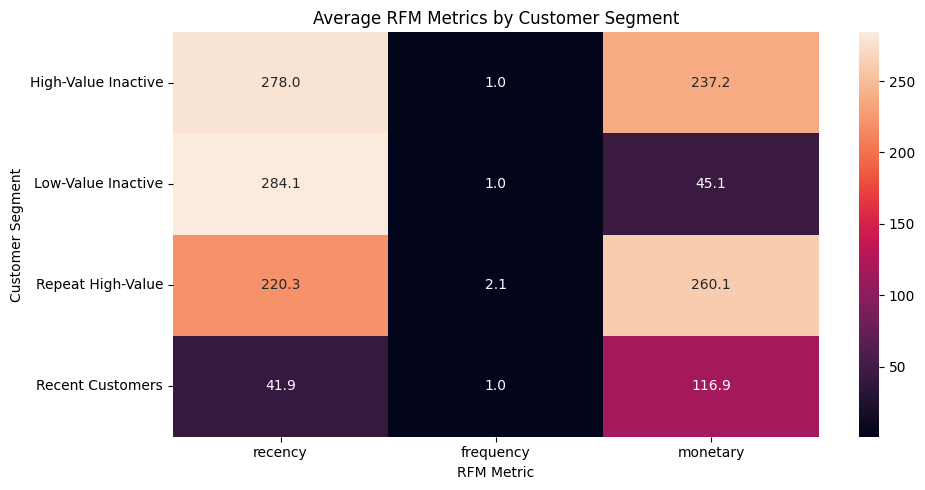

In [120]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    segment_metrics,
    annot=True,
    fmt='.1f'
)

plt.title('Average RFM Metrics by Customer Segment')
plt.xlabel('RFM Metric')
plt.ylabel('Customer Segment')

plt.tight_layout()
plt.show()

In [121]:
#Segment revenue contribution

In [122]:
    segment_revenue = (
    customer_segments
    .groupby('segment')['monetary']
    .sum()
    .sort_values(ascending=False)
)

segment_revenue

segment
High-Value Inactive    8953745.40
Recent Customers       1882768.95
Low-Value Inactive     1656575.01
Repeat High-Value       728408.75
Name: monetary, dtype: float64

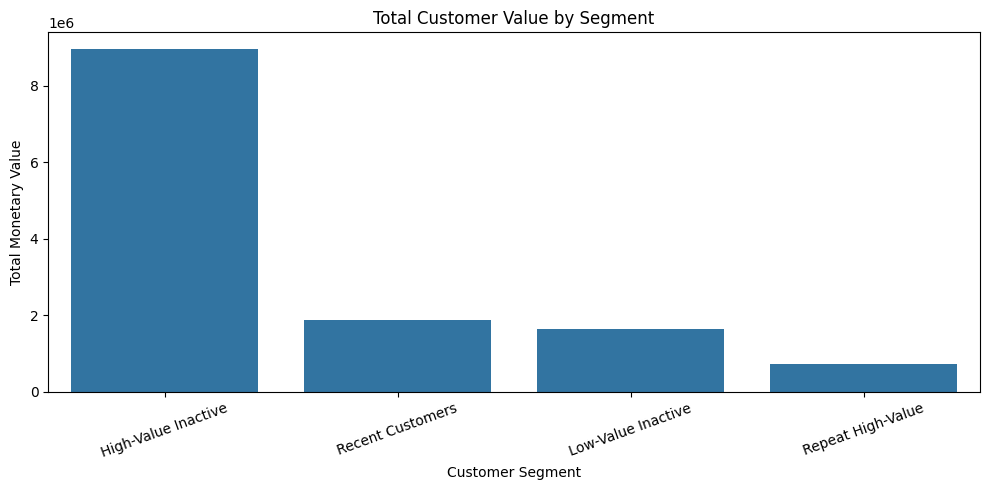

In [123]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=segment_revenue.index,
    y=segment_revenue.values
)

plt.title('Total Customer Value by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Monetary Value')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

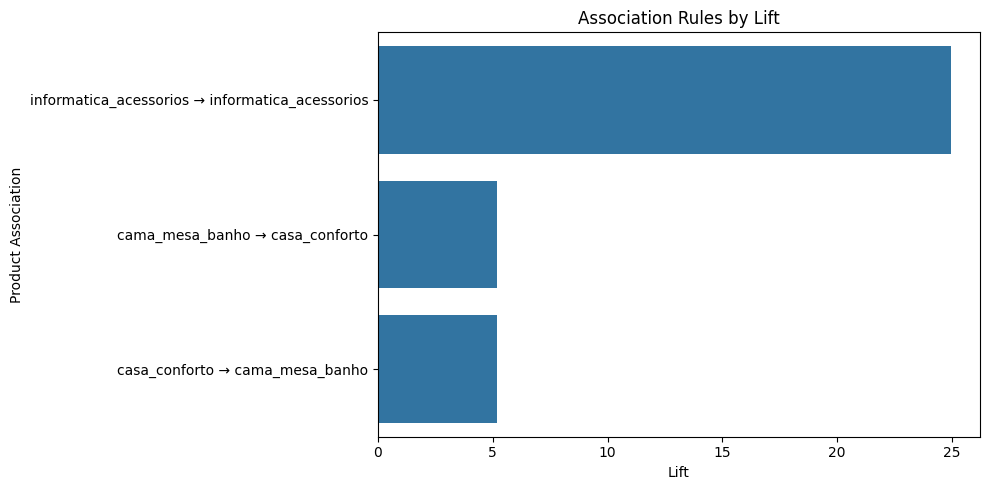

In [124]:
plt.figure(figsize=(10, 5))

rule_labels = (
    association_rules_final['antecedents']
    + ' → '
    + association_rules_final['consequents']
)

sns.barplot(
    x=association_rules_final['Lift'],
    y=rule_labels
)

plt.title('Association Rules by Lift')
plt.xlabel('Lift')
plt.ylabel('Product Association')

plt.tight_layout()
plt.show()

In [125]:
recommendations = pd.DataFrame({
    'Segment': [
        'High-Value Inactive',
        'Low-Value Inactive',
        'Repeat High-Value',
        'Recent Customers'
    ],
    'Characteristics': [
        'High spending, low purchase frequency, long time since purchase',
        'Low spending, one purchase, long time since purchase',
        'Highest repeat behavior and high spending',
        'Recent purchase, moderate spending, mostly one-time buyers'
    ],
    'Recommended Action': [
        'Run personalized win-back campaigns and recommend products related to previous purchases.',
        'Use low-cost promotions, entry-level offers, and targeted cross-selling.',
        'Prioritize loyalty programs, exclusive offers, cross-selling, and premium recommendations.',
        'Use post-purchase recommendations and second-purchase incentives to build repeat behavior.'
    ]
})

recommendations

,Segment,Characteristics,Recommended Action
0,High-Value Inactive,"High spending, low purchase frequency, long ti...",Run personalized win-back campaigns and recomm...
1,Low-Value Inactive,"Low spending, one purchase, long time since pu...","Use low-cost promotions, entry-level offers, a..."
2,Repeat High-Value,Highest repeat behavior and high spending,"Prioritize loyalty programs, exclusive offers,..."
3,Recent Customers,"Recent purchase, moderate spending, mostly one...",Use post-purchase recommendations and second-p...


In [126]:
print("Top association rules for recommendation:")
display(
    association_rules_final[
        ['antecedents', 'consequents',
         'Support (%)', 'Confidence (%)', 'Lift']
    ].head(10)
)

Top association rules for recommendation:


,antecedents,consequents,Support (%),Confidence (%),Lift
3,informatica_acessorios,informatica_acessorios,0.273,30.91,24.97
2,informatica_acessorios,informatica_acessorios,0.273,22.08,24.97
1,cama_mesa_banho,casa_conforto,0.233,6.36,5.17
0,casa_conforto,cama_mesa_banho,0.233,18.95,5.17


In [127]:
print("FINAL CLUSTERING COMPARISON")

display(
    clustering_comparison.sort_values(
        'Silhouette_Score',
        ascending=False
    )
)

FINAL CLUSTERING COMPARISON


,Algorithm,Silhouette_Score
1,DBSCAN,0.690632
0,K-Means,0.391516
2,Hierarchical,0.320740


In [128]:
final_clustering_summary = pd.DataFrame({
    'Cluster': [0, 1, 2, 3],
    'Segment': [
        'High-Value Inactive',
        'Low-Value Inactive',
        'Repeat High-Value',
        'Recent Customers'
    ],
    'Customers': [
        37747,
        36704,
        2801,
        16106
    ],
    'Percentage': [
        40.43,
        39.32,
        3.00,
        17.25
    ],
    'Avg Recency': [
        278.01,
        284.11,
        220.29,
        41.89
    ],
    'Avg Frequency': [
        1.00,
        1.00,
        2.11,
        1.00
    ],
    'Avg Monetary': [
        237.20,
        45.13,
        260.05,
        116.90
    ]
})

final_clustering_summary

,Cluster,Segment,Customers,Percentage,Avg Recency,Avg Frequency,Avg Monetary
0,0,High-Value Inactive,37747,40.43,278.01,1.00,237.20
1,1,Low-Value Inactive,36704,39.32,284.11,1.00,45.13
2,2,Repeat High-Value,2801,3.00,220.29,2.11,260.05
3,3,Recent Customers,16106,17.25,41.89,1.00,116.90


In [129]:
final_algorithm_comparison = pd.DataFrame({
    'Algorithm': [
        'K-Means',
        'DBSCAN',
        'Hierarchical Clustering'
    ],
    'Number of Clusters': [
        4,
        4,
        4
    ],
    'Silhouette Score': [
        0.3915,
        0.6906,
        0.3207
    ],
    'Primary Result': [
        'Four interpretable customer segments',
        'One dominant cluster with 97% of customers',
        'Less separated clusters'
    ]
})

final_algorithm_comparison

,Algorithm,Number of Clusters,Silhouette Score,Primary Result
0,K-Means,4,0.3915,Four interpretable customer segments
1,DBSCAN,4,0.6906,One dominant cluster with 97% of customers
2,Hierarchical Clustering,4,0.3207,Less separated clusters
